In [1]:
# ============================================================
# Notebook 02: Missingness and Data Quality EDA
# Step 1: Setup and load final datasets
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

# Final processed files from Notebook 01
DATA_DIR = Path.home() / "Desktop" / "DISSERTATION" / "Codes" / "data" / "processed"

print("Using DATA_DIR:")
print(DATA_DIR)

print("\nFiles found in DATA_DIR:")
for file in DATA_DIR.glob("*.csv"):
    print(file.name)

panel_path = DATA_DIR / "selected_pm25_temperature_panel.csv"
eda_panel_path = DATA_DIR / "selected_pm25_temperature_panel_for_eda.csv"
metadata_path = DATA_DIR / "selected_station_metadata.csv"
pm25_wide_path = DATA_DIR / "selected_pm25_wide_panel.csv"
temperature_wide_path = DATA_DIR / "selected_temperature_wide_panel.csv"

# Check files exist before loading
required_files = [
    panel_path,
    eda_panel_path,
    metadata_path,
    pm25_wide_path,
    temperature_wide_path
]

for file in required_files:
    if not file.exists():
        raise FileNotFoundError(f"Missing file: {file}")

print("\nAll required files found.")

# Load data
panel = pd.read_csv(panel_path)
eda_panel = pd.read_csv(eda_panel_path)
metadata = pd.read_csv(metadata_path)
pm25_wide = pd.read_csv(pm25_wide_path)
temperature_wide = pd.read_csv(temperature_wide_path)

# Convert datetime columns
panel["Datetime"] = pd.to_datetime(panel["Datetime"])
eda_panel["Datetime"] = pd.to_datetime(eda_panel["Datetime"])
pm25_wide["Datetime"] = pd.to_datetime(pm25_wide["Datetime"])
temperature_wide["Datetime"] = pd.to_datetime(temperature_wide["Datetime"])

print("\nLoaded dataset shapes:")
print("Main panel shape:", panel.shape)
print("EDA panel shape:", eda_panel.shape)
print("Metadata shape:", metadata.shape)
print("PM2.5 wide shape:", pm25_wide.shape)
print("Temperature wide shape:", temperature_wide.shape)

display(panel.head())
display(metadata)

Using DATA_DIR:
C:\Users\Msi\Desktop\DISSERTATION\Codes\data\processed

Files found in DATA_DIR:
final_missingness_report.csv
pm25_status_audit.csv
pm25_temperature_missingness_overlap.csv
selected_pm25_temperature_panel.csv
selected_pm25_temperature_panel_for_eda.csv
selected_pm25_wide_panel.csv
selected_station_metadata.csv
selected_temperature_wide_panel.csv
station_year_missingness_summary.csv
temperature_availability_audit.csv
temperature_status_audit.csv
top3_idw_weights.csv
top3_nearest_neighbours.csv

All required files found.

Loaded dataset shapes:
Main panel shape: (219120, 5)
EDA panel shape: (219120, 12)
Metadata shape: (5, 7)
PM2.5 wide shape: (43824, 6)
Temperature wide shape: (43824, 6)


,Station,Datetime,RawYear,PM25,Temperature
0,London Bexley,2021-01-01 01:00:00,2021,39.552,-1.2
1,London Bexley,2021-01-01 02:00:00,2021,52.359,-1.9
2,London Bexley,2021-01-01 03:00:00,2021,20.920,-2.3
3,London Bexley,2021-01-01 04:00:00,2021,15.943,-2.8
4,London Bexley,2021-01-01 05:00:00,2021,17.076,-3.2


,Station,Latitude,Longitude,SiteType,Zone,Agglomeration,LocalAuthority
0,London Bexley,51.466030,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley
1,London Harlington,51.488790,-0.441614,Urban Industrial,Greater London,Greater London Urban Area,Hillingdon
2,London Honor Oak Park,51.449674,-0.037418,Urban Background,Greater London,Greater London Urban Area,Lewisham
3,London Marylebone Road,51.522530,-0.154611,Urban Traffic,Greater London,Greater London Urban Area,Westminster
4,London N. Kensington,51.521050,-0.213419,Urban Background,Greater London,Greater London Urban Area,Kensington


In [2]:
# ============================================================
# Step 2: Structural validation of final analytical dataset
# ============================================================

expected_stations = [
    "London Bexley",
    "London Harlington",
    "London Honor Oak Park",
    "London Marylebone Road",
    "London N. Kensington"
]

expected_years = [2021, 2022, 2023, 2024, 2025]

hours_per_year = {
    2021: 8760,
    2022: 8760,
    2023: 8760,
    2024: 8784,
    2025: 8760
}

expected_timestamps_per_station = sum(hours_per_year[y] for y in expected_years)
expected_rows = expected_timestamps_per_station * len(expected_stations)

print("Expected timestamps per station:", expected_timestamps_per_station)
print("Expected total rows:", expected_rows)
print("Actual total rows:", len(panel))

print("\nStations in dataset:")
print(sorted(panel["Station"].unique()))

print("\nYears in dataset:")
print(sorted(panel["RawYear"].unique()))

duplicate_count = panel.duplicated(["Station", "Datetime"]).sum()
print("\nDuplicate Station + Datetime rows:", duplicate_count)

station_counts = (
    panel.groupby("Station")
    .size()
    .reset_index(name="Rows")
)

year_counts = (
    panel.groupby("RawYear")
    .size()
    .reset_index(name="Rows")
)

print("\nRows per station:")
display(station_counts)

print("\nRows per year:")
display(year_counts)

# Validation checks
assert len(panel) == expected_rows, "Unexpected number of rows"
assert duplicate_count == 0, "Duplicate Station + Datetime rows found"
assert sorted(panel["Station"].unique()) == sorted(expected_stations), "Unexpected station list"
assert sorted(panel["RawYear"].unique()) == expected_years, "Unexpected years"
assert station_counts["Rows"].nunique() == 1, "Not all stations have equal row counts"

print("\nStructural validation passed.")

Expected timestamps per station: 43824
Expected total rows: 219120
Actual total rows: 219120

Stations in dataset:
['London Bexley', 'London Harlington', 'London Honor Oak Park', 'London Marylebone Road', 'London N. Kensington']

Years in dataset:
[2021, 2022, 2023, 2024, 2025]

Duplicate Station + Datetime rows: 0

Rows per station:


,Station,Rows
0,London Bexley,43824
1,London Harlington,43824
2,London Honor Oak Park,43824
3,London Marylebone Road,43824
4,London N. Kensington,43824



Rows per year:


,RawYear,Rows
0,2021,43800
1,2022,43800
2,2023,43800
3,2024,43920
4,2025,43800



Structural validation passed.


In [3]:
# ============================================================
# Step 3: Create temporal features for EDA
# ============================================================

# A separate EDA copy is used so the original modelling panel remains unchanged.
# This keeps the modelling dataset clean while allowing us to add analysis-only variables.
eda = panel.copy()

# Time-based variables are created because PM2.5 is strongly time-dependent.
# These features allow later analysis of annual, monthly, daily and hourly patterns.
eda["Year"] = eda["Datetime"].dt.year
eda["Month"] = eda["Datetime"].dt.month
eda["Hour"] = eda["Datetime"].dt.hour
eda["DayOfWeek"] = eda["Datetime"].dt.day_name()

# Seasons are added to support higher-level temporal analysis.
# This is useful because air pollution and meteorological conditions often vary by season.
def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

# The season label will later help compare PM2.5 levels and missingness across the year.
eda["Season"] = eda["Month"].apply(assign_season)

# Previewing the dataset confirms that the analysis-only temporal features were added correctly.
print("EDA dataset shape:", eda.shape)
display(eda.head())

EDA dataset shape: (219120, 10)


,Station,Datetime,RawYear,PM25,Temperature,Year,Month,Hour,DayOfWeek,Season
0,London Bexley,2021-01-01 01:00:00,2021,39.552,-1.2,2021,1,1,Friday,Winter
1,London Bexley,2021-01-01 02:00:00,2021,52.359,-1.9,2021,1,2,Friday,Winter
2,London Bexley,2021-01-01 03:00:00,2021,20.920,-2.3,2021,1,3,Friday,Winter
3,London Bexley,2021-01-01 04:00:00,2021,15.943,-2.8,2021,1,4,Friday,Winter
4,London Bexley,2021-01-01 05:00:00,2021,17.076,-3.2,2021,1,5,Friday,Winter


In [4]:
# ============================================================
# Step 4: Dataset overview summary
# ============================================================

# This summary gives a high-level profile of the final analytical dataset.
# It is useful before detailed EDA because it confirms the study period,
# station coverage, total observations, missingness level, and basic value ranges.

summary = {
    # The date range confirms that the dataset covers the intended 2021-2025 period.
    "Start datetime": eda["Datetime"].min(),
    "End datetime": eda["Datetime"].max(),

    # Station and year counts show the spatial and temporal scope of the dataset.
    "Number of stations": eda["Station"].nunique(),
    "Number of RawYears": eda["RawYear"].nunique(),
    "Total station-hour rows": len(eda),

    # PM2.5 is the target variable, so its availability is central to the imputation study.
    # This tells us how much real observed data is available before artificial masking.
    "PM2.5 valid observations": eda["PM25"].notna().sum(),
    "PM2.5 missing observations": eda["PM25"].isna().sum(),
    "PM2.5 capture (%)": round(eda["PM25"].notna().mean() * 100, 2),

    # Temperature is an auxiliary predictor, so its availability affects whether it can be used reliably in models.
    "Temperature valid observations": eda["Temperature"].notna().sum(),
    "Temperature missing observations": eda["Temperature"].isna().sum(),
    "Temperature capture (%)": round(eda["Temperature"].notna().mean() * 100, 2),

    # Basic minimum and maximum values help identify obvious data quality problems.
    # PM2.5 should not be negative, while negative temperature is possible because it is measured in Celsius.
    "Minimum PM2.5": eda["PM25"].min(),
    "Maximum PM2.5": eda["PM25"].max(),
    "Minimum Temperature": eda["Temperature"].min(),
    "Maximum Temperature": eda["Temperature"].max()
}

# Convert the summary dictionary into a table so it can be easily inspected and later reported.
summary_df = pd.DataFrame(summary.items(), columns=["Metric", "Value"])

display(summary_df)

,Metric,Value
0,Start datetime,2021-01-01 01:00:00
1,End datetime,2026-01-01 00:00:00
2,Number of stations,5
3,Number of RawYears,5
4,Total station-hour rows,219120
5,PM2.5 valid observations,214013
6,PM2.5 missing observations,5107
7,PM2.5 capture (%),97.67
8,Temperature valid observations,214920
9,Temperature missing observations,4200


In [5]:
# ============================================================
# Step 4.1: Basic plausibility checks
# ============================================================

# PM2.5 concentrations cannot physically be below zero.
# This check confirms that negative PM2.5 values were correctly handled during preprocessing.
negative_pm25_count = (eda["PM25"] < 0).sum()

# Negative temperature values are not automatically errors because the unit is Celsius.
# This check is kept only to understand the data range, not to remove those values.
negative_temperature_count = (eda["Temperature"] < 0).sum()

print("Negative PM2.5 values:", negative_pm25_count)
print("Negative temperature values:", negative_temperature_count)

# Descriptive statistics provide a first view of central tendency, spread, and extreme values.
# This helps decide whether later distribution plots and outlier checks are needed.
print("\nPM2.5 descriptive statistics:")
display(eda["PM25"].describe())

print("\nTemperature descriptive statistics:")
display(eda["Temperature"].describe())

Negative PM2.5 values: 0
Negative temperature values: 8560

PM2.5 descriptive statistics:


count    214013.000000
mean          8.638835
std           7.431767
min           0.000000
25%           4.109000
50%           6.415000
75%          10.542000
max         133.868000
Name: PM25, dtype: float64


Temperature descriptive statistics:


count    214920.000000
mean         10.458662
std           6.084173
min          -7.500000
25%           6.200000
50%          10.300000
75%          14.700000
max          31.900000
Name: Temperature, dtype: float64

In [6]:
# ============================================================
# Step 5: Overall natural missingness summary
# ============================================================

# Natural missingness must be measured before artificial masking is introduced.
# This is important because imputation models should later be evaluated only on
# artificially masked observed PM2.5 values, not on values that were already missing.

eda["PM25_Missing"] = eda["PM25"].isna()
eda["Temperature_Missing"] = eda["Temperature"].isna()

# This summary shows the overall availability of the target variable and auxiliary predictor.
# PM2.5 availability affects how much ground truth is available for masking and evaluation.
# Temperature availability affects whether it can be used reliably as a model input.
missingness_summary = pd.DataFrame({
    "Variable": ["PM2.5", "Temperature"],
    "Total rows": [len(eda), len(eda)],
    "Valid observations": [
        eda["PM25"].notna().sum(),
        eda["Temperature"].notna().sum()
    ],
    "Missing observations": [
        eda["PM25"].isna().sum(),
        eda["Temperature"].isna().sum()
    ],
    "Missing (%)": [
        round(eda["PM25"].isna().mean() * 100, 2),
        round(eda["Temperature"].isna().mean() * 100, 2)
    ],
    "Capture (%)": [
        round(eda["PM25"].notna().mean() * 100, 2),
        round(eda["Temperature"].notna().mean() * 100, 2)
    ]
})

display(missingness_summary)

,Variable,Total rows,Valid observations,Missing observations,Missing (%),Capture (%)
0,PM2.5,219120,214013,5107,2.33,97.67
1,Temperature,219120,214920,4200,1.92,98.08


In [7]:
# ============================================================
# Step 5.1: Missingness overlap between PM2.5 and temperature
# ============================================================

# The overlap between missing PM2.5 and missing temperature is important for modelling.
# If both variables are missing at the same time, temperature cannot help impute PM2.5
# at those specific timestamps.

eda["Both_Missing"] = eda["PM25_Missing"] & eda["Temperature_Missing"]
eda["PM25_Missing_Temperature_Available"] = eda["PM25_Missing"] & (~eda["Temperature_Missing"])
eda["Temperature_Missing_PM25_Available"] = eda["Temperature_Missing"] & (~eda["PM25_Missing"])

overlap_summary = pd.DataFrame({
    "Missingness category": [
        "PM2.5 missing",
        "Temperature missing",
        "Both PM2.5 and Temperature missing",
        "PM2.5 missing but Temperature available",
        "Temperature missing but PM2.5 available"
    ],
    "Rows": [
        eda["PM25_Missing"].sum(),
        eda["Temperature_Missing"].sum(),
        eda["Both_Missing"].sum(),
        eda["PM25_Missing_Temperature_Available"].sum(),
        eda["Temperature_Missing_PM25_Available"].sum()
    ]
})

overlap_summary["Percentage of total rows"] = round(
    overlap_summary["Rows"] / len(eda) * 100, 2
)

display(overlap_summary)

,Missingness category,Rows,Percentage of total rows
0,PM2.5 missing,5107,2.33
1,Temperature missing,4200,1.92
2,Both PM2.5 and Temperature missing,105,0.05
3,PM2.5 missing but Temperature available,5002,2.28
4,Temperature missing but PM2.5 available,4095,1.87


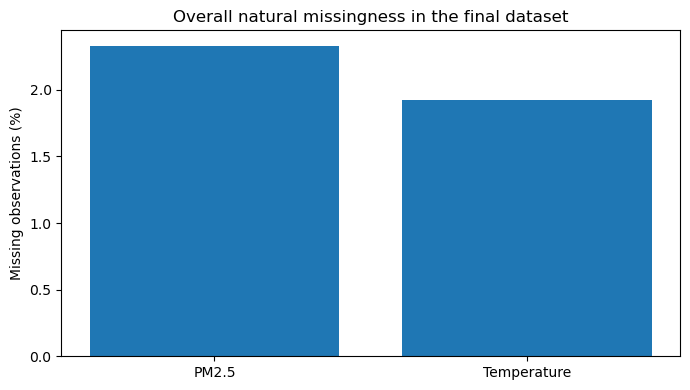

In [8]:
# ============================================================
# Step 5.2: Visualise overall missingness
# ============================================================

# A simple bar chart makes the overall missingness level easier to compare.
# This supports the argument that the final dataset is mostly complete before masking.

plt.figure(figsize=(7, 4))

plt.bar(
    missingness_summary["Variable"],
    missingness_summary["Missing (%)"]
)

plt.ylabel("Missing observations (%)")
plt.title("Overall natural missingness in the final dataset")

plt.tight_layout()
plt.show()

## Step 6: Station-level missingness analysis

This step examines natural missingness separately for each monitoring station. This is important because PM2.5 imputation difficulty may not be equal across stations. A station with higher natural missingness may represent a more challenging imputation setting, while stations with high data capture provide stronger ground truth for later artificial masking experiments.

The analysis also compares PM2.5 and temperature availability by station. PM2.5 is the target variable, while temperature is used as an auxiliary predictor. Therefore, temperature availability helps assess whether it can reliably support later machine learning and spatio-temporal models.

In [9]:
# ============================================================
# Step 6: Station-level missingness summary
# ============================================================

# Station-level missingness is examined because imputation difficulty may vary by monitoring site.
# A station with more natural missing PM2.5 values may be harder to impute and may need closer attention
# when comparing model performance later.

station_missingness = (
    eda.groupby("Station")
    .agg(
        Total_rows=("PM25", "size"),

        # PM2.5 is the target variable, so its missingness directly affects how much observed
        # ground truth is available for artificial masking and later evaluation.
        PM25_valid=("PM25", lambda x: x.notna().sum()),
        PM25_missing=("PM25", lambda x: x.isna().sum()),

        # Temperature is an auxiliary predictor, so its availability affects whether it can
        # support PM2.5 imputation consistently across stations.
        Temperature_valid=("Temperature", lambda x: x.notna().sum()),
        Temperature_missing=("Temperature", lambda x: x.isna().sum())
    )
    .reset_index()
)

# Percentages make the station comparison easier because all stations have the same number of rows.
station_missingness["PM25_missing_%"] = round(
    station_missingness["PM25_missing"] / station_missingness["Total_rows"] * 100, 2
)

station_missingness["PM25_capture_%"] = round(
    station_missingness["PM25_valid"] / station_missingness["Total_rows"] * 100, 2
)

station_missingness["Temperature_missing_%"] = round(
    station_missingness["Temperature_missing"] / station_missingness["Total_rows"] * 100, 2
)

station_missingness["Temperature_capture_%"] = round(
    station_missingness["Temperature_valid"] / station_missingness["Total_rows"] * 100, 2
)

# Sorting by PM2.5 missingness highlights which station may be the most challenging
# for later imputation experiments.
station_missingness = station_missingness.sort_values(
    "PM25_missing_%",
    ascending=False
)

display(station_missingness)

,Station,Total_rows,PM25_valid,PM25_missing,Temperature_valid,Temperature_missing,PM25_missing_%,PM25_capture_%,Temperature_missing_%,Temperature_capture_%
3,London Marylebone Road,43824,39900,3924,42984,840,8.95,91.05,1.92,98.08
2,London Honor Oak Park,43824,43282,542,42984,840,1.24,98.76,1.92,98.08
4,London N. Kensington,43824,43594,230,42984,840,0.52,99.48,1.92,98.08
0,London Bexley,43824,43607,217,42984,840,0.50,99.50,1.92,98.08
1,London Harlington,43824,43630,194,42984,840,0.44,99.56,1.92,98.08


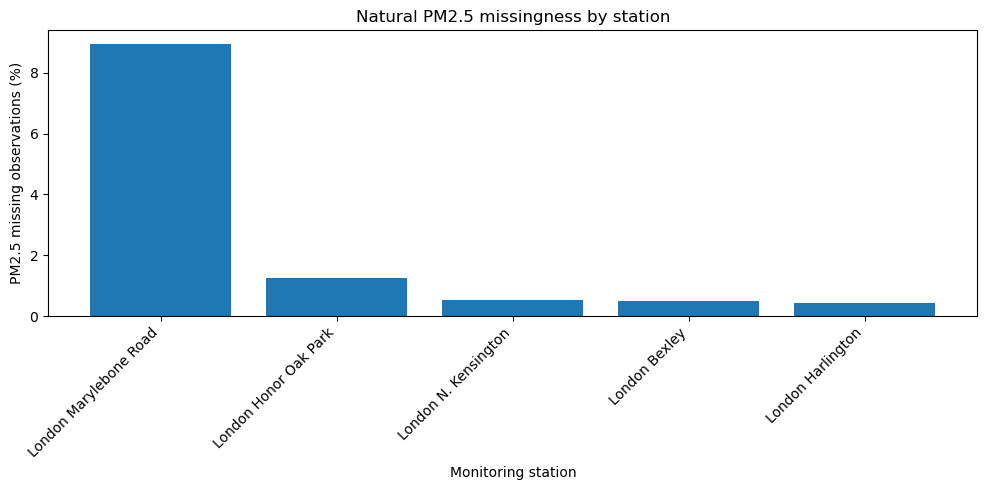

In [10]:
# ============================================================
# Step 6.1: Visualise PM2.5 missingness by station
# ============================================================

# A bar chart makes it easier to compare natural PM2.5 missingness across stations.
# This is useful for identifying whether some stations may create more difficult
# imputation cases than others.

plt.figure(figsize=(10, 5))

plt.bar(
    station_missingness["Station"],
    station_missingness["PM25_missing_%"]
)

plt.ylabel("PM2.5 missing observations (%)")
plt.xlabel("Monitoring station")
plt.title("Natural PM2.5 missingness by station")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

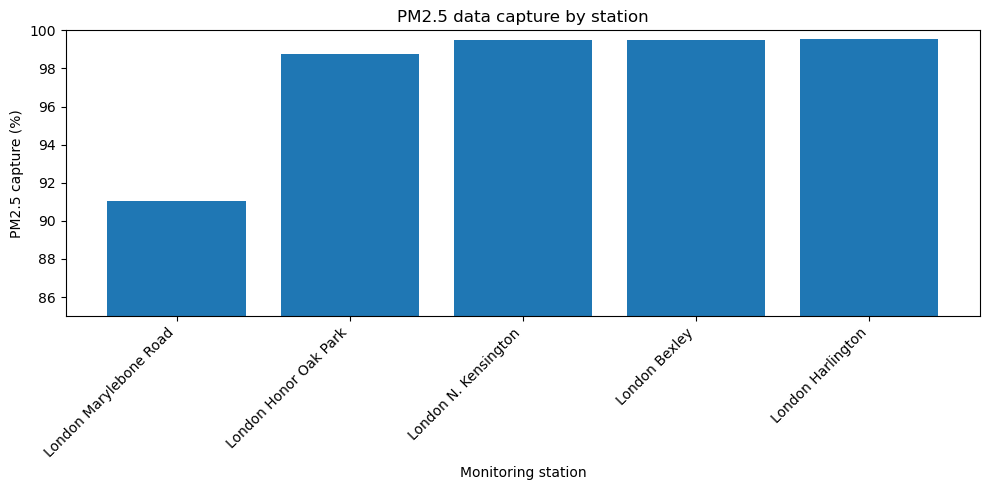

In [11]:
# ============================================================
# Step 6.2: Visualise PM2.5 capture by station
# ============================================================

# Capture percentage is shown because the station selection method was based on annual PM2.5 data capture.
# This figure confirms that the selected stations remain highly complete across the full study period.

station_capture = station_missingness.sort_values(
    "PM25_capture_%",
    ascending=True
)

plt.figure(figsize=(10, 5))

plt.bar(
    station_capture["Station"],
    station_capture["PM25_capture_%"]
)

plt.ylabel("PM2.5 capture (%)")
plt.xlabel("Monitoring station")
plt.title("PM2.5 data capture by station")

plt.xticks(rotation=45, ha="right")
plt.ylim(85, 100)
plt.tight_layout()
plt.show()

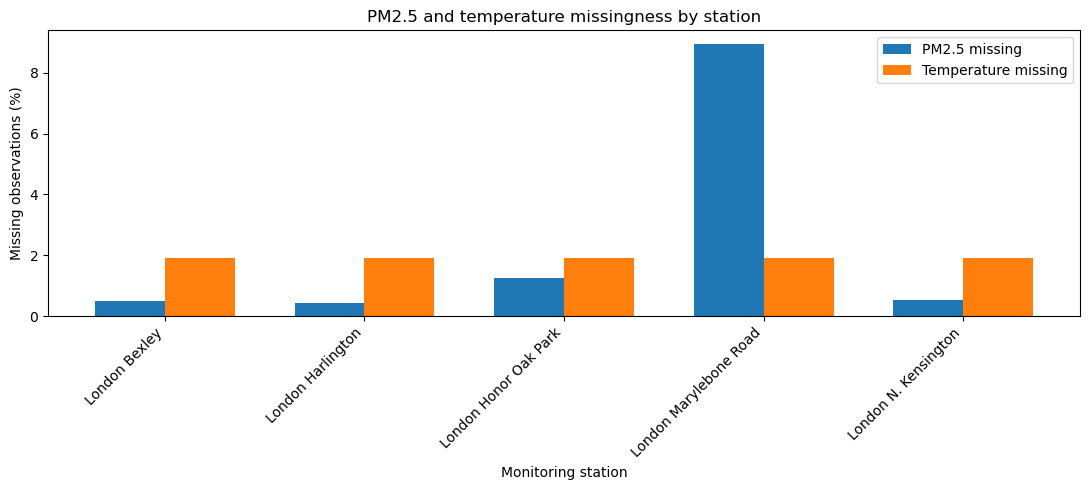

In [12]:
# ============================================================
# Step 6.3: Compare PM2.5 and temperature missingness by station
# ============================================================

# This comparison checks whether the auxiliary temperature variable has similar or better availability
# than PM2.5 at each station. This matters because temperature can only support PM2.5 imputation
# when it is available at the relevant timestamps.

comparison_plot = station_missingness.sort_values("Station")

x = np.arange(len(comparison_plot["Station"]))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(
    x - width / 2,
    comparison_plot["PM25_missing_%"],
    width,
    label="PM2.5 missing"
)

plt.bar(
    x + width / 2,
    comparison_plot["Temperature_missing_%"],
    width,
    label="Temperature missing"
)

plt.ylabel("Missing observations (%)")
plt.xlabel("Monitoring station")
plt.title("PM2.5 and temperature missingness by station")

plt.xticks(x, comparison_plot["Station"], rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# Step 6.4: Station-year PM2.5 missingness summary
# ============================================================

# Station-year missingness is examined because annual problems can be hidden
# when only the full-period station average is reported.
# This is important for imputation because a model may perform differently
# in years with more missing data or different monitoring conditions.

station_year_missingness = (
    eda.groupby(["Station", "RawYear"])
    .agg(
        Total_rows=("PM25", "size"),
        PM25_valid=("PM25", lambda x: x.notna().sum()),
        PM25_missing=("PM25", lambda x: x.isna().sum())
    )
    .reset_index()
)

station_year_missingness["PM25_missing_%"] = round(
    station_year_missingness["PM25_missing"] /
    station_year_missingness["Total_rows"] * 100,
    2
)

station_year_missingness["PM25_capture_%"] = round(
    station_year_missingness["PM25_valid"] /
    station_year_missingness["Total_rows"] * 100,
    2
)

display(station_year_missingness)

,Station,RawYear,Total_rows,PM25_valid,PM25_missing,PM25_missing_%,PM25_capture_%
0,London Bexley,2021,8760,8754,6,0.07,99.93
1,London Bexley,2022,8760,8711,49,0.56,99.44
2,London Bexley,2023,8760,8740,20,0.23,99.77
3,London Bexley,2024,8784,8772,12,0.14,99.86
4,London Bexley,2025,8760,8630,130,1.48,98.52
5,London Harlington,2021,8760,8703,57,0.65,99.35
6,London Harlington,2022,8760,8694,66,0.75,99.25
7,London Harlington,2023,8760,8749,11,0.13,99.87
8,London Harlington,2024,8784,8756,28,0.32,99.68
9,London Harlington,2025,8760,8728,32,0.37,99.63


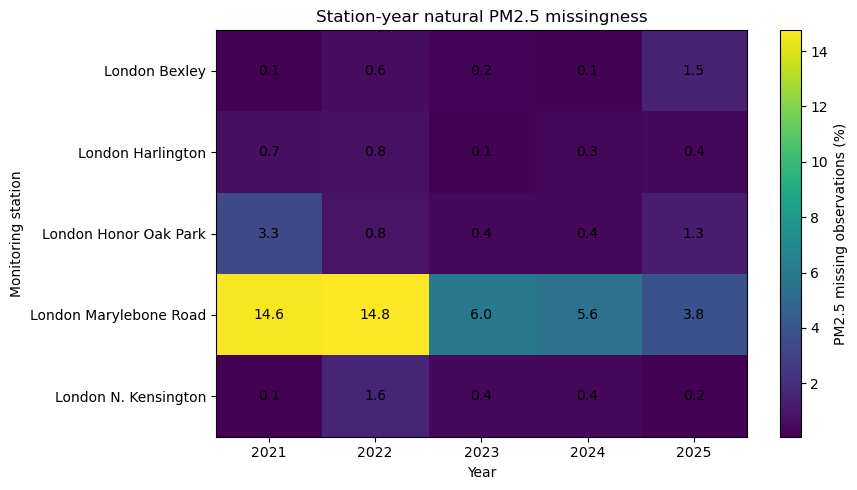

In [14]:
# ============================================================
# Step 6.5: Heatmap-style view of station-year PM2.5 missingness
# ============================================================

# A station-year heatmap helps identify whether missingness is concentrated
# in particular years or particular stations. This is more informative than
# a single overall missingness percentage.

missingness_matrix = station_year_missingness.pivot(
    index="Station",
    columns="RawYear",
    values="PM25_missing_%"
)

plt.figure(figsize=(9, 5))

plt.imshow(missingness_matrix, aspect="auto")

plt.xticks(
    ticks=np.arange(len(missingness_matrix.columns)),
    labels=missingness_matrix.columns
)

plt.yticks(
    ticks=np.arange(len(missingness_matrix.index)),
    labels=missingness_matrix.index
)

plt.colorbar(label="PM2.5 missing observations (%)")
plt.title("Station-year natural PM2.5 missingness")
plt.xlabel("Year")
plt.ylabel("Monitoring station")

# Add percentage values inside the cells so the figure is readable without needing the table.
for i in range(missingness_matrix.shape[0]):
    for j in range(missingness_matrix.shape[1]):
        value = missingness_matrix.iloc[i, j]
        plt.text(j, i, f"{value:.1f}", ha="center", va="center")

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# Step 6.6: Highest PM2.5 missingness station-years
# ============================================================

# The heatmap shows the overall station-year pattern visually, but this table
# highlights the most incomplete station-year combinations directly.
# This is useful because later model performance may be weaker in periods or stations
# where the original monitoring data already had more natural missingness.

highest_missing_station_years = (
    station_year_missingness
    .sort_values("PM25_missing_%", ascending=False)
    .head(10)
)

display(highest_missing_station_years)

,Station,RawYear,Total_rows,PM25_valid,PM25_missing,PM25_missing_%,PM25_capture_%
16,London Marylebone Road,2022,8760,7468,1292,14.75,85.25
15,London Marylebone Road,2021,8760,7478,1282,14.63,85.37
17,London Marylebone Road,2023,8760,8233,527,6.02,93.98
18,London Marylebone Road,2024,8784,8292,492,5.60,94.40
19,London Marylebone Road,2025,8760,8429,331,3.78,96.22
10,London Honor Oak Park,2021,8760,8470,290,3.31,96.69
21,London N. Kensington,2022,8760,8622,138,1.58,98.42
4,London Bexley,2025,8760,8630,130,1.48,98.52
14,London Honor Oak Park,2025,8760,8650,110,1.26,98.74
11,London Honor Oak Park,2022,8760,8686,74,0.84,99.16


### Interpretation

Station-level missingness shows that the final dataset is highly complete overall, but PM2.5 missingness is not evenly distributed across stations. London Marylebone Road has the highest natural PM2.5 missingness at 8.95%, while the other stations have much lower missingness, mostly below 1.5%. This suggests that imputation difficulty may vary between stations.

London Marylebone Road should not be removed because it still exceeds the 85% data capture threshold. Instead, it provides a useful challenging station for later imputation evaluation. This supports reporting model performance by station as well as overall.

Temperature missingness is low and consistent across stations, supporting its use as an auxiliary predictor in later machine-learning and spatio-temporal models.

## Step 7: Temporal missingness patterns

This step examines whether natural PM2.5 missingness varies over time. This is important because missing values in air-quality monitoring data may occur as isolated points, seasonal patterns, maintenance periods, or longer operational interruptions.

Understanding temporal missingness helps justify the later controlled masking design. If missingness is not purely random, then evaluating models under both point gaps and block gaps is more realistic than using only random missing values.

In [16]:
# ============================================================
# Step 7: PM2.5 missingness by year
# ============================================================

# Year-level missingness is examined because later modelling uses a chronological split.
# If a particular year has unusually high natural missingness, this may affect how we
# interpret validation or test performance.

year_missingness = (
    eda.groupby("RawYear")
    .agg(
        Total_rows=("PM25", "size"),
        PM25_valid=("PM25", lambda x: x.notna().sum()),
        PM25_missing=("PM25", lambda x: x.isna().sum())
    )
    .reset_index()
)

year_missingness["PM25_missing_%"] = round(
    year_missingness["PM25_missing"] /
    year_missingness["Total_rows"] * 100,
    2
)

year_missingness["PM25_capture_%"] = round(
    year_missingness["PM25_valid"] /
    year_missingness["Total_rows"] * 100,
    2
)

display(year_missingness)

,RawYear,Total_rows,PM25_valid,PM25_missing,PM25_missing_%,PM25_capture_%
0,2021,43800,42157,1643,3.75,96.25
1,2022,43800,42181,1619,3.70,96.30
2,2023,43800,43174,626,1.43,98.57
3,2024,43920,43320,600,1.37,98.63
4,2025,43800,43181,619,1.41,98.59


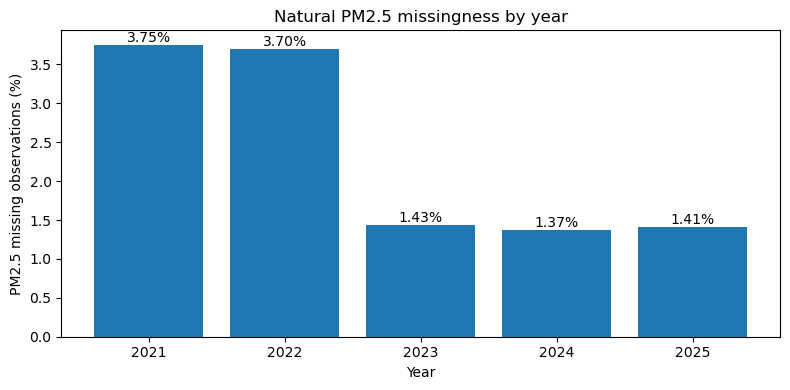

In [17]:
# ============================================================
# Step 7.1: Visualise PM2.5 missingness by year
# ============================================================

# This figure shows whether natural PM2.5 missingness changes across the study years.
# This matters because the planned train-validation-test split is chronological,
# so year-level differences may affect model evaluation.

plt.figure(figsize=(8, 4))

bars = plt.bar(
    year_missingness["RawYear"].astype(str),
    year_missingness["PM25_missing_%"]
)

plt.ylabel("PM2.5 missing observations (%)")
plt.xlabel("Year")
plt.title("Natural PM2.5 missingness by year")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# Step 7.2: PM2.5 missingness by month
# ============================================================

# Month-level missingness helps identify whether missing data is concentrated
# in particular parts of the year.
# This can suggest seasonal maintenance patterns or periods where monitoring was less complete.

month_missingness = (
    eda.groupby("Month")
    .agg(
        Total_rows=("PM25", "size"),
        PM25_valid=("PM25", lambda x: x.notna().sum()),
        PM25_missing=("PM25", lambda x: x.isna().sum())
    )
    .reset_index()
)

month_missingness["PM25_missing_%"] = round(
    month_missingness["PM25_missing"] /
    month_missingness["Total_rows"] * 100,
    2
)

month_missingness["PM25_capture_%"] = round(
    month_missingness["PM25_valid"] /
    month_missingness["Total_rows"] * 100,
    2
)

display(month_missingness)

,Month,Total_rows,PM25_valid,PM25_missing,PM25_missing_%,PM25_capture_%
0,1,18600,17368,1232,6.62,93.38
1,2,16920,16277,643,3.80,96.20
2,3,18600,18321,279,1.50,98.50
3,4,18000,17840,160,0.89,99.11
4,5,18600,18363,237,1.27,98.73
5,6,18000,17830,170,0.94,99.06
6,7,18600,17933,667,3.59,96.41
7,8,18600,18390,210,1.13,98.87
8,9,18000,17285,715,3.97,96.03
9,10,18600,18371,229,1.23,98.77


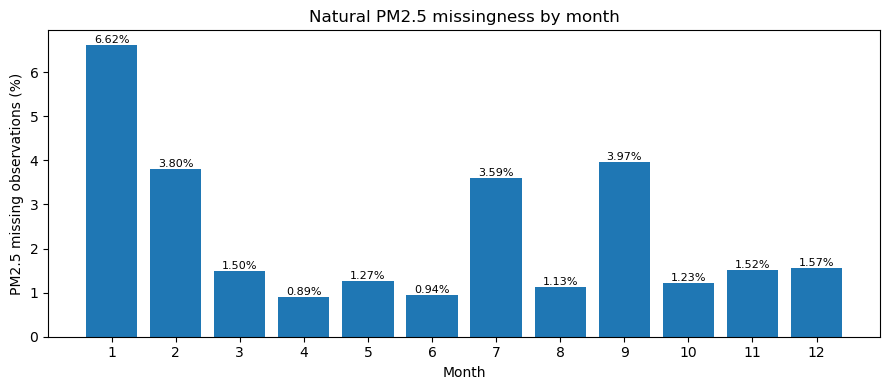

In [19]:
# ============================================================
# Step 7.3: Visualise PM2.5 missingness by month
# ============================================================

# A monthly figure helps show whether natural missingness is temporally clustered.
# If missingness is concentrated in some months, then artificial masking should not
# be treated only as a purely random problem.

plt.figure(figsize=(9, 4))

bars = plt.bar(
    month_missingness["Month"].astype(str),
    month_missingness["PM25_missing_%"]
)

plt.ylabel("PM2.5 missing observations (%)")
plt.xlabel("Month")
plt.title("Natural PM2.5 missingness by month")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# Step 7.4: PM2.5 missingness by season
# ============================================================

# Season-level missingness provides a broader view than monthly missingness.
# This is useful because air pollution and monitoring conditions may vary seasonally,
# and later model performance may differ across seasonal contexts.

season_order = ["Winter", "Spring", "Summer", "Autumn"]

season_missingness = (
    eda.groupby("Season")
    .agg(
        Total_rows=("PM25", "size"),
        PM25_valid=("PM25", lambda x: x.notna().sum()),
        PM25_missing=("PM25", lambda x: x.isna().sum())
    )
    .reset_index()
)

season_missingness["PM25_missing_%"] = round(
    season_missingness["PM25_missing"] /
    season_missingness["Total_rows"] * 100,
    2
)

season_missingness["PM25_capture_%"] = round(
    season_missingness["PM25_valid"] /
    season_missingness["Total_rows"] * 100,
    2
)

season_missingness["Season"] = pd.Categorical(
    season_missingness["Season"],
    categories=season_order,
    ordered=True
)

season_missingness = season_missingness.sort_values("Season")

display(season_missingness)

,Season,Total_rows,PM25_valid,PM25_missing,PM25_missing_%,PM25_capture_%
3,Winter,54120,51953,2167,4.00,96.00
1,Spring,55200,54524,676,1.22,98.78
2,Summer,55200,54153,1047,1.90,98.10
0,Autumn,54600,53383,1217,2.23,97.77


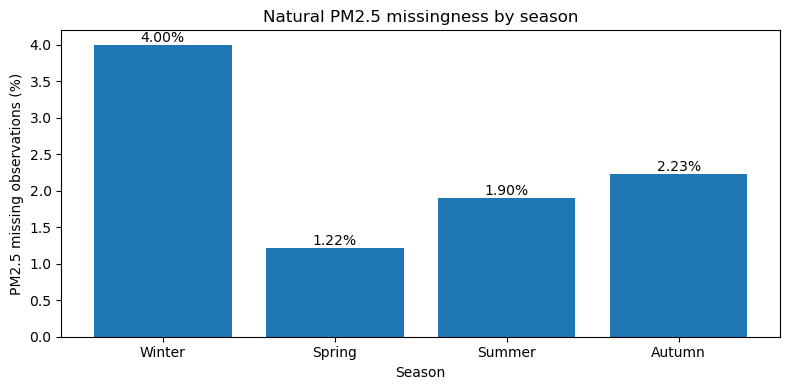

In [21]:
# ============================================================
# Step 7.5: Visualise PM2.5 missingness by season
# ============================================================

# Seasonal missingness is shown because a model may face different imputation
# conditions in winter, spring, summer, and autumn.
# This helps connect EDA to later temporal evaluation and robustness discussion.

plt.figure(figsize=(8, 4))

bars = plt.bar(
    season_missingness["Season"].astype(str),
    season_missingness["PM25_missing_%"]
)

plt.ylabel("PM2.5 missing observations (%)")
plt.xlabel("Season")
plt.title("Natural PM2.5 missingness by season")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Step 7 interpretation

Temporal missingness analysis shows that natural PM2.5 missingness is not evenly distributed across the study period. Year-level results show higher missingness in 2021 and 2022, with 3.75% and 3.70% missing PM2.5 observations respectively. Missingness is lower and more stable from 2023 to 2025, remaining around 1.4%.

Month-level results show that missingness is highest in January, September, February and July. January has the highest missingness at 6.62%, while April and June have the lowest missingness, below 1%. This suggests that natural missingness is temporally clustered rather than evenly distributed across the year.

Season-level analysis shows that winter has the highest missingness at 4.00%, followed by autumn, summer and spring. This is important because imputation difficulty may vary across seasonal contexts. However, the exact operational causes of these temporal patterns cannot be confirmed from the PM2.5 values alone.

These findings support the later use of both random point masking and structured block-gap masking. Since real missingness shows temporal variation, evaluating models only under purely random missingness would be too limited. The temporal missingness analysis therefore provides methodological support for testing imputation models under more realistic missingness scenarios.

## Step 8: Consecutive PM2.5 missing gap length analysis

This step examines whether natural PM2.5 missing values occur as isolated points or as consecutive gaps. This is important because imputation difficulty depends strongly on gap length. A single missing hour may be easier to reconstruct using nearby observations, while longer gaps require stronger temporal, spatial or meteorological information.

This analysis helps justify the later artificial masking design, especially the use of 24-hour and 72-hour block gaps. These scenarios represent more realistic monitoring interruptions than purely random point missingness.

In [22]:
# ============================================================
# Step 8: Identify consecutive PM2.5 missing gaps
# ============================================================

# Consecutive missing gaps are analysed because imputation difficulty depends not only
# on how many PM2.5 values are missing, but also on whether they occur as isolated points
# or as longer continuous gaps.

gap_data = eda[["Station", "Datetime", "RawYear", "PM25_Missing"]].copy()

# Sorting by station and time is necessary because consecutive gaps only make sense
# when each station's observations are in chronological order.
gap_data = gap_data.sort_values(["Station", "Datetime"]).reset_index(drop=True)

# A new run starts whenever the missingness status changes from observed to missing
# or from missing to observed within the same station.
gap_data["Missing_status_changed"] = (
    gap_data.groupby("Station")["PM25_Missing"]
    .transform(lambda x: x.ne(x.shift()))
)

# Run_ID groups consecutive rows with the same missingness status.
# This allows us to measure the length of each continuous missing block.
gap_data["Run_ID"] = (
    gap_data.groupby("Station")["Missing_status_changed"]
    .cumsum()
)

# Keep only the runs where PM2.5 is missing.
# Each row in missing_gaps represents one consecutive missing PM2.5 gap.
missing_gaps = (
    gap_data[gap_data["PM25_Missing"]]
    .groupby(["Station", "Run_ID"])
    .agg(
        Gap_start=("Datetime", "min"),
        Gap_end=("Datetime", "max"),
        Start_year=("RawYear", "min"),
        End_year=("RawYear", "max"),
        Gap_length_hours=("PM25_Missing", "size")
    )
    .reset_index()
)

display(missing_gaps.head())
print("Number of consecutive missing PM2.5 gaps:", len(missing_gaps))

,Station,Run_ID,Gap_start,Gap_end,Start_year,End_year,Gap_length_hours
0,London Bexley,2,2021-01-13 12:00:00,2021-01-13 12:00:00,2021,2021,1
1,London Bexley,4,2021-03-11 13:00:00,2021-03-11 13:00:00,2021,2021,1
2,London Bexley,6,2021-07-14 11:00:00,2021-07-14 11:00:00,2021,2021,1
3,London Bexley,8,2021-07-14 21:00:00,2021-07-14 22:00:00,2021,2021,2
4,London Bexley,10,2021-09-22 12:00:00,2021-09-22 12:00:00,2021,2021,1


Number of consecutive missing PM2.5 gaps: 455


In [23]:
# ============================================================
# Step 8.1: Summary of PM2.5 missing gap lengths
# ============================================================

# This summary shows whether natural missingness is mostly made of short gaps
# or whether longer block gaps are present.
# This directly informs the design of later artificial masking experiments.

gap_length_summary = pd.DataFrame({
    "Metric": [
        "Number of missing gaps",
        "Total missing PM2.5 hours",
        "Mean gap length (hours)",
        "Median gap length (hours)",
        "Maximum gap length (hours)",
        "Gaps at least 24 hours",
        "Gaps at least 72 hours"
    ],
    "Value": [
        len(missing_gaps),
        missing_gaps["Gap_length_hours"].sum(),
        round(missing_gaps["Gap_length_hours"].mean(), 2),
        missing_gaps["Gap_length_hours"].median(),
        missing_gaps["Gap_length_hours"].max(),
        (missing_gaps["Gap_length_hours"] >= 24).sum(),
        (missing_gaps["Gap_length_hours"] >= 72).sum()
    ]
})

display(gap_length_summary)

,Metric,Value
0,Number of missing gaps,455.00
1,Total missing PM2.5 hours,5107.00
2,Mean gap length (hours),11.22
3,Median gap length (hours),2.00
4,Maximum gap length (hours),821.00
5,Gaps at least 24 hours,41.00
6,Gaps at least 72 hours,20.00


In [24]:
# ============================================================
# Step 8.2: Categorise PM2.5 missing gaps by length
# ============================================================

# Gap categories make the results easier to interpret.
# They separate isolated missing hours from longer monitoring interruptions,
# which are more difficult for imputation models.

def classify_gap_length(hours):
    if hours == 1:
        return "1 hour"
    elif hours <= 6:
        return "2-6 hours"
    elif hours <= 23:
        return "7-23 hours"
    elif hours <= 71:
        return "24-71 hours"
    else:
        return "72+ hours"

missing_gaps["Gap_category"] = missing_gaps["Gap_length_hours"].apply(classify_gap_length)

gap_category_summary = (
    missing_gaps.groupby("Gap_category")
    .agg(
        Number_of_gaps=("Gap_length_hours", "size"),
        Total_missing_hours=("Gap_length_hours", "sum")
    )
    .reset_index()
)

# Use a logical order so the table follows increasing gap severity.
gap_order = ["1 hour", "2-6 hours", "7-23 hours", "24-71 hours", "72+ hours"]

gap_category_summary["Gap_category"] = pd.Categorical(
    gap_category_summary["Gap_category"],
    categories=gap_order,
    ordered=True
)

gap_category_summary = gap_category_summary.sort_values("Gap_category")

gap_category_summary["Percentage_of_gaps"] = round(
    gap_category_summary["Number_of_gaps"] /
    gap_category_summary["Number_of_gaps"].sum() * 100,
    2
)

gap_category_summary["Percentage_of_missing_hours"] = round(
    gap_category_summary["Total_missing_hours"] /
    gap_category_summary["Total_missing_hours"].sum() * 100,
    2
)

display(gap_category_summary)

,Gap_category,Number_of_gaps,Total_missing_hours,Percentage_of_gaps,Percentage_of_missing_hours
0,1 hour,227,227,49.89,4.44
1,2-6 hours,170,430,37.36,8.42
3,7-23 hours,17,265,3.74,5.19
2,24-71 hours,21,847,4.62,16.59
4,72+ hours,20,3338,4.40,65.36


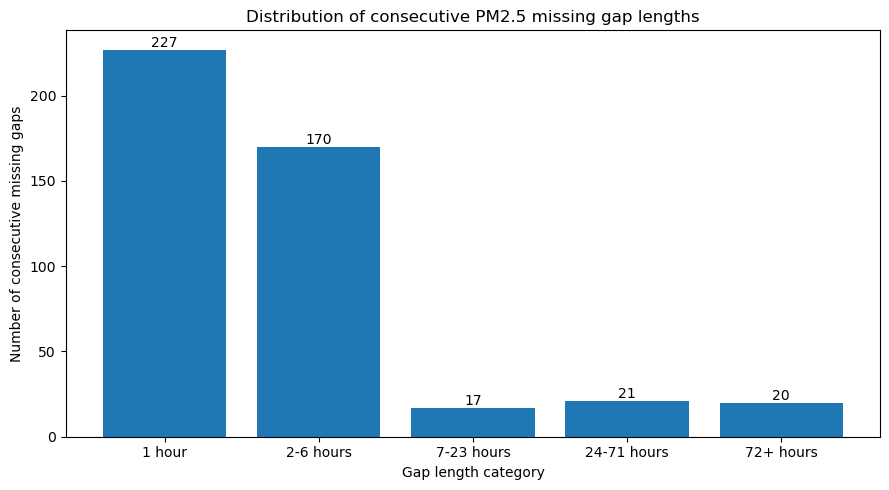

In [25]:
# ============================================================
# Step 8.3: Visualise PM2.5 missing gap length categories
# ============================================================

# This figure shows whether missingness is dominated by short isolated gaps
# or by longer block gaps. This matters because different imputation methods
# may perform differently depending on gap length.

plt.figure(figsize=(9, 5))

bars = plt.bar(
    gap_category_summary["Gap_category"].astype(str),
    gap_category_summary["Number_of_gaps"]
)

plt.ylabel("Number of consecutive missing gaps")
plt.xlabel("Gap length category")
plt.title("Distribution of consecutive PM2.5 missing gap lengths")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# Step 8.4: Missing gap length summary by station
# ============================================================

# Gap length is summarised by station because some stations may not only have
# more missing values, but also longer missing blocks.
# Longer gaps usually create harder imputation tasks than short isolated gaps.

gap_by_station = (
    missing_gaps.groupby("Station")
    .agg(
        Number_of_gaps=("Gap_length_hours", "size"),
        Total_missing_hours=("Gap_length_hours", "sum"),
        Mean_gap_length=("Gap_length_hours", "mean"),
        Median_gap_length=("Gap_length_hours", "median"),
        Max_gap_length=("Gap_length_hours", "max"),
        Gaps_24h_or_more=("Gap_length_hours", lambda x: (x >= 24).sum()),
        Gaps_72h_or_more=("Gap_length_hours", lambda x: (x >= 72).sum())
    )
    .reset_index()
)

gap_by_station["Mean_gap_length"] = round(gap_by_station["Mean_gap_length"], 2)

# Sorting by maximum gap length highlights stations with the most severe continuous interruptions.
gap_by_station = gap_by_station.sort_values("Max_gap_length", ascending=False)

display(gap_by_station)

,Station,Number_of_gaps,Total_missing_hours,Mean_gap_length,Median_gap_length,Max_gap_length,Gaps_24h_or_more,Gaps_72h_or_more
3,London Marylebone Road,301,3924,13.04,1.0,821,32,17
2,London Honor Oak Park,48,542,11.29,2.0,265,4,1
4,London N. Kensington,31,230,7.42,2.0,120,2,1
0,London Bexley,29,217,7.48,2.0,117,1,1
1,London Harlington,46,194,4.22,2.0,51,2,0


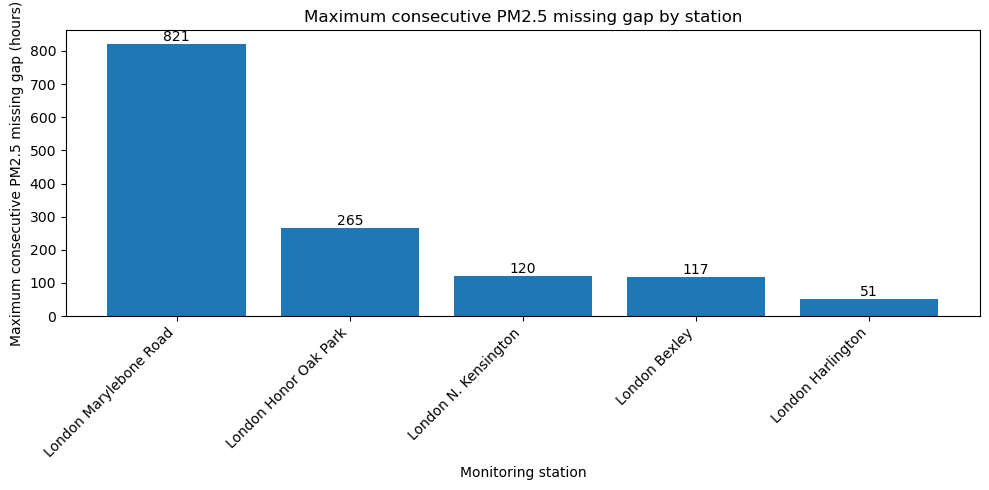

In [27]:
# ============================================================
# Step 8.5: Visualise maximum PM2.5 missing gap length by station
# ============================================================

# Maximum gap length shows the most severe continuous interruption at each station.
# This helps identify which stations may be most challenging under block-gap imputation scenarios.

plot_data = gap_by_station.sort_values("Max_gap_length", ascending=False)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    plot_data["Station"],
    plot_data["Max_gap_length"]
)

plt.ylabel("Maximum consecutive PM2.5 missing gap (hours)")
plt.xlabel("Monitoring station")
plt.title("Maximum consecutive PM2.5 missing gap by station")

plt.xticks(rotation=45, ha="right")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [28]:
# ============================================================
# Step 8.6: Longest consecutive PM2.5 missing gaps
# ============================================================

# The longest natural gaps are listed to show concrete examples of structured missingness.
# This supports the later use of artificial temporal block-gap masking scenarios.

longest_missing_gaps = (
    missing_gaps
    .sort_values("Gap_length_hours", ascending=False)
    .head(10)
)

display(longest_missing_gaps)

,Station,Run_ID,Gap_start,Gap_end,Start_year,End_year,Gap_length_hours,Gap_category
159,London Marylebone Road,74,2021-12-21 09:00:00,2022-01-24 13:00:00,2021,2022,821,72+ hours
153,London Marylebone Road,62,2021-09-05 11:00:00,2021-09-24 10:00:00,2021,2021,456,72+ hours
75,London Honor Oak Park,2,2021-02-11 13:00:00,2021-02-22 13:00:00,2021,2021,265,72+ hours
150,London Marylebone Road,56,2021-07-10 19:00:00,2021-07-21 07:00:00,2021,2021,253,72+ hours
161,London Marylebone Road,78,2022-02-02 11:00:00,2022-02-10 15:00:00,2022,2022,197,72+ hours
165,London Marylebone Road,86,2022-02-25 22:00:00,2022-03-04 10:00:00,2022,2022,157,72+ hours
429,London N. Kensington,12,2022-01-27 01:00:00,2022-02-01 00:00:00,2022,2022,120,72+ hours
28,London Bexley,58,2025-09-07 14:00:00,2025-09-12 10:00:00,2025,2025,117,72+ hours
192,London Marylebone Road,140,2022-11-14 09:00:00,2022-11-18 15:00:00,2022,2022,103,72+ hours
209,London Marylebone Road,174,2023-04-21 08:00:00,2023-04-24 16:00:00,2023,2023,81,72+ hours


### Step 8 interpretation

The consecutive gap analysis shows that PM2.5 missingness occurs both as short isolated gaps and as longer continuous blocks. The dataset contains 455 consecutive missing gaps covering 5,107 missing PM2.5 hours. The median gap length is only 2 hours, showing that many missing events are short. However, the maximum gap length is 821 hours, which indicates that severe monitoring interruptions also exist.

Short gaps are most common by count: 1-hour gaps represent 49.89% of all gaps, and 2–6 hour gaps represent 37.36%. However, long gaps dominate the total missing data volume. Gaps of 72+ hours represent only 4.40% of all gaps, but account for 65.36% of all missing PM2.5 hours.

This finding strongly supports the later masking design. Random point masking is justified because many gaps are short, while 24-hour and 72-hour block-gap scenarios are necessary because most missing hours come from longer continuous interruptions. London Marylebone Road is the most challenging station, with the largest number of missing hours and the longest continuous gap, so later model performance should also be considered at station.
ation.

## Additional check: Temperature availability during PM2.5 gaps

This section checks whether temperature remains available during natural PM2.5 missing gaps. This is important because temperature is planned as an auxiliary predictor in later models.

Temperature availability in the full dataset is not enough by itself. For imputation, the key question is whether temperature is available at the same timestamps where PM2.5 is missing. This is especially important for longer 24-hour and 72-hour PM2.5 gaps, where auxiliary information may become more valuable.

In [29]:
# ============================================================
# Additional check: Temperature availability during PM2.5 gaps
# ============================================================

# This analysis checks whether temperature is available during PM2.5 missing gaps.
# This matters because temperature can only support PM2.5 imputation if it is observed
# at the same timestamps where PM2.5 is missing.

gap_temperature_records = []

for _, gap in missing_gaps.iterrows():
    station = gap["Station"]
    gap_start = gap["Gap_start"]
    gap_end = gap["Gap_end"]
    gap_length = gap["Gap_length_hours"]

    # Select the exact station-time rows covered by this natural PM2.5 missing gap.
    gap_rows = eda[
        (eda["Station"] == station)
        & (eda["Datetime"] >= gap_start)
        & (eda["Datetime"] <= gap_end)
    ]

    temperature_valid = gap_rows["Temperature"].notna().sum()
    temperature_missing = gap_rows["Temperature"].isna().sum()

    gap_temperature_records.append({
        "Station": station,
        "Gap_start": gap_start,
        "Gap_end": gap_end,
        "Gap_length_hours": gap_length,
        "Temperature_valid_hours": temperature_valid,
        "Temperature_missing_hours": temperature_missing,
        "Temperature_capture_during_gap_%": round(
            temperature_valid / len(gap_rows) * 100, 2
        ) if len(gap_rows) > 0 else np.nan
    })

gap_temperature_availability = pd.DataFrame(gap_temperature_records)

display(gap_temperature_availability.head())

,Station,Gap_start,Gap_end,Gap_length_hours,Temperature_valid_hours,Temperature_missing_hours,Temperature_capture_during_gap_%
0,London Bexley,2021-01-13 12:00:00,2021-01-13 12:00:00,1,1,0,100.0
1,London Bexley,2021-03-11 13:00:00,2021-03-11 13:00:00,1,1,0,100.0
2,London Bexley,2021-07-14 11:00:00,2021-07-14 11:00:00,1,1,0,100.0
3,London Bexley,2021-07-14 21:00:00,2021-07-14 22:00:00,2,2,0,100.0
4,London Bexley,2021-09-22 12:00:00,2021-09-22 12:00:00,1,1,0,100.0


In [30]:
# ============================================================
# Temperature availability by PM2.5 gap severity
# ============================================================

# The planned masking design includes 24-hour and 72-hour block gaps.
# Therefore, temperature availability is summarised separately for short gaps,
# 24-71 hour gaps, and 72+ hour gaps.

def classify_gap_severity(hours):
    if hours >= 72:
        return "72h_or_more"
    elif hours >= 24:
        return "24h_to_71h"
    else:
        return "Less_than_24h"

gap_temperature_availability["Gap_severity"] = (
    gap_temperature_availability["Gap_length_hours"].apply(classify_gap_severity)
)

temperature_during_gap_summary = (
    gap_temperature_availability.groupby("Gap_severity")
    .agg(
        Number_of_PM25_gaps=("Gap_length_hours", "count"),
        Total_PM25_missing_hours=("Gap_length_hours", "sum"),
        Temperature_valid_hours=("Temperature_valid_hours", "sum"),
        Temperature_missing_hours=("Temperature_missing_hours", "sum")
    )
    .reset_index()
)

temperature_during_gap_summary["Temperature_capture_during_PM25_gaps_%"] = round(
    temperature_during_gap_summary["Temperature_valid_hours"]
    / temperature_during_gap_summary["Total_PM25_missing_hours"] * 100,
    2
)

display(temperature_during_gap_summary)

,Gap_severity,Number_of_PM25_gaps,Total_PM25_missing_hours,Temperature_valid_hours,Temperature_missing_hours,Temperature_capture_during_PM25_gaps_%
0,24h_to_71h,21,847,847,0,100.00
1,72h_or_more,20,3338,3252,86,97.42
2,Less_than_24h,414,922,903,19,97.94


In [31]:
# ============================================================
# Temperature availability during PM2.5 gaps by station
# ============================================================

# Station-level results show whether temperature support is consistent across monitoring sites.
# This is important because some stations may lose PM2.5 and temperature at the same time,
# which would reduce the usefulness of temperature as an auxiliary predictor.

temperature_during_gap_by_station = (
    gap_temperature_availability.groupby("Station")
    .agg(
        Number_of_PM25_gaps=("Gap_length_hours", "count"),
        Total_PM25_missing_hours=("Gap_length_hours", "sum"),
        Temperature_valid_hours=("Temperature_valid_hours", "sum"),
        Temperature_missing_hours=("Temperature_missing_hours", "sum")
    )
    .reset_index()
)

temperature_during_gap_by_station["Temperature_capture_during_PM25_gaps_%"] = round(
    temperature_during_gap_by_station["Temperature_valid_hours"]
    / temperature_during_gap_by_station["Total_PM25_missing_hours"] * 100,
    2
)

display(temperature_during_gap_by_station)

,Station,Number_of_PM25_gaps,Total_PM25_missing_hours,Temperature_valid_hours,Temperature_missing_hours,Temperature_capture_during_PM25_gaps_%
0,London Bexley,29,217,217,0,100.00
1,London Harlington,46,194,194,0,100.00
2,London Honor Oak Park,48,542,540,2,99.63
3,London Marylebone Road,301,3924,3821,103,97.38
4,London N. Kensington,31,230,230,0,100.00


### Temperature availability during PM2.5 gaps interpretation

Temperature remains highly available during natural PM2.5 missing gaps. For short PM2.5 gaps below 24 hours, temperature capture is 97.94%. For 24-71 hour gaps, temperature is fully available, with 100% capture. For longer gaps of 72 hours or more, temperature capture remains high at 97.42%.

Station-level results show that temperature availability during PM2.5 gaps is also consistent across sites. London Bexley, London Harlington and London N. Kensington have complete temperature availability during PM2.5 missing periods. London Marylebone Road has the lowest value, but temperature capture is still high at 97.38%.

These results support the use of temperature as an auxiliary predictor in later imputation models. Temperature is usually available at the moments where PM2.5 needs to be imputed, including during longer block gaps.

## Additional check: Observed PM2.5 run-length distribution

This section examines continuous runs where PM2.5 is observed. This is the inverse of the previous missing-gap analysis.

This check is important because artificial block masking can only be applied to originally observed PM2.5 values. If there are enough continuous observed runs of at least 24 and 72 hours in each station and split, then the planned block-gap masking design is feasible.

In [32]:
# ============================================================
# Additional check: Create split labels for observed-run analysis
# ============================================================

# Split labels are needed because masking feasibility should be checked separately
# for training, validation and test periods.
# This helps ensure that 24-hour and 72-hour block masking is feasible in each split.

run_data = eda.copy()

def assign_split(raw_year):
    if raw_year in [2021, 2022, 2023]:
        return "Train"
    elif raw_year == 2024:
        return "Validation"
    elif raw_year == 2025:
        return "Test"
    else:
        return "Outside split"

run_data["Split"] = run_data["RawYear"].apply(assign_split)

# Keep only the modelling period.
run_data = run_data[run_data["Split"] != "Outside split"].copy()

display(run_data["Split"].value_counts())

Split
Train         131400
Validation     43920
Test           43800
Name: count, dtype: int64

In [33]:
# ============================================================
# Additional check: Calculate continuous observed PM2.5 runs
# ============================================================

# This identifies continuous periods where PM2.5 is observed.
# These observed runs are the candidate regions where artificial point or block
# missingness can be created while still keeping known ground truth for evaluation.

observed_run_records = []

for (station, split), group in run_data.groupby(["Station", "Split"]):
    group = group.sort_values("Datetime").copy()

    # True means PM2.5 is available at that timestamp.
    group["PM25_observed"] = group["PM25"].notna()

    # A new run starts whenever the observed/missing status changes.
    # This separates continuous observed periods from missing periods.
    group["Run_ID"] = (
        group["PM25_observed"] != group["PM25_observed"].shift()
    ).cumsum()

    observed_runs_station_split = (
        group[group["PM25_observed"]]
        .groupby("Run_ID")
        .agg(
            Run_start=("Datetime", "min"),
            Run_end=("Datetime", "max"),
            Run_length_hours=("PM25", "size")
        )
        .reset_index()
    )

    for _, run in observed_runs_station_split.iterrows():
        observed_run_records.append({
            "Station": station,
            "Split": split,
            "Run_start": run["Run_start"],
            "Run_end": run["Run_end"],
            "Run_length_hours": run["Run_length_hours"]
        })

observed_runs = pd.DataFrame(observed_run_records)

display(observed_runs.head())
print("Number of continuous observed PM2.5 runs:", len(observed_runs))

,Station,Split,Run_start,Run_end,Run_length_hours
0,London Bexley,Test,2025-01-01 01:00:00,2025-01-22 12:00:00,516
1,London Bexley,Test,2025-01-22 15:00:00,2025-02-05 13:00:00,335
2,London Bexley,Test,2025-02-05 17:00:00,2025-03-08 04:00:00,732
3,London Bexley,Test,2025-03-08 09:00:00,2025-07-14 14:00:00,3078
4,London Bexley,Test,2025-07-14 16:00:00,2025-07-28 11:00:00,332


Number of continuous observed PM2.5 runs: 470


In [34]:
# ============================================================
# Additional check: Observed-run summary by station and split
# ============================================================

# This summary checks whether each station and split has enough continuous observed
# PM2.5 periods for 24-hour and 72-hour block masking.
# Potential windows count overlapping possible start positions for each block length.

observed_run_summary = (
    observed_runs.groupby(["Split", "Station"])
    .agg(
        Number_of_observed_runs=("Run_length_hours", "count"),
        Total_observed_hours=("Run_length_hours", "sum"),
        Mean_run_length=("Run_length_hours", "mean"),
        Median_run_length=("Run_length_hours", "median"),
        Max_run_length=("Run_length_hours", "max"),
        Runs_24h_or_more=("Run_length_hours", lambda x: (x >= 24).sum()),
        Runs_72h_or_more=("Run_length_hours", lambda x: (x >= 72).sum()),
        Potential_24h_mask_windows=("Run_length_hours", lambda x: np.maximum(x - 24 + 1, 0).sum()),
        Potential_72h_mask_windows=("Run_length_hours", lambda x: np.maximum(x - 72 + 1, 0).sum())
    )
    .reset_index()
)

observed_run_summary[["Mean_run_length", "Median_run_length"]] = (
    observed_run_summary[["Mean_run_length", "Median_run_length"]].round(2)
)

split_order = ["Train", "Validation", "Test"]

observed_run_summary["Split"] = pd.Categorical(
    observed_run_summary["Split"],
    categories=split_order,
    ordered=True
)

observed_run_summary = observed_run_summary.sort_values(["Split", "Station"])

display(observed_run_summary)

,Split,Station,Number_of_observed_runs,Total_observed_hours,Mean_run_length,Median_run_length,Max_run_length,Runs_24h_or_more,Runs_72h_or_more,Potential_24h_mask_windows,Potential_72h_mask_windows
5,Train,London Bexley,18,26205,1455.83,1304.0,4105,17,17,25805,24989
6,Train,London Harlington,21,26146,1245.05,865.0,4779,21,20,25663,24682
7,Train,London Honor Oak Park,31,25883,834.94,887.0,1844,29,28,25182,23790
8,Train,London Marylebone Road,123,23179,188.45,139.0,909,108,92,20513,15730
9,Train,London N. Kensington,21,26099,1242.81,1091.0,3997,20,19,25628,24689
10,Validation,London Bexley,7,8772,1253.14,1164.0,2886,7,7,8611,8275
11,Validation,London Harlington,14,8756,625.43,277.5,2587,14,13,8434,7772
12,Validation,London Honor Oak Park,8,8749,1093.62,864.5,3478,8,8,8565,8181
13,Validation,London Marylebone Road,69,8292,120.17,99.0,436,55,42,6871,4538
14,Validation,London N. Kensington,6,8751,1458.50,1325.0,2974,6,6,8613,8325


In [35]:
# ============================================================
# Additional check: Overall block-masking feasibility summary
# ============================================================

# This compact table answers whether the planned 24-hour and 72-hour block masking
# experiments are feasible in each modelling split.
# The minimum station window columns are especially important because the weakest station
# determines whether masking is feasible across the whole network.

masking_feasibility_summary = (
    observed_run_summary.groupby("Split", observed=False)
    .agg(
        Stations=("Station", "nunique"),
        Total_runs_24h_or_more=("Runs_24h_or_more", "sum"),
        Total_runs_72h_or_more=("Runs_72h_or_more", "sum"),
        Total_potential_24h_windows=("Potential_24h_mask_windows", "sum"),
        Total_potential_72h_windows=("Potential_72h_mask_windows", "sum"),
        Minimum_station_24h_windows=("Potential_24h_mask_windows", "min"),
        Minimum_station_72h_windows=("Potential_72h_mask_windows", "min")
    )
    .reset_index()
)

display(masking_feasibility_summary)

,Split,Stations,Total_runs_24h_or_more,Total_runs_72h_or_more,Total_potential_24h_windows,Total_potential_72h_windows,Minimum_station_24h_windows,Minimum_station_72h_windows
0,Train,5,195,176,122791,113880,20513,15730
1,Validation,5,90,76,41094,37091,6871,4538
2,Test,5,114,81,40183,35596,6350,3584


### Observed-run-length interpretation

The observed-run analysis confirms that the planned artificial block masking design is feasible. Across all modelling splits, there are many continuous observed PM2.5 periods of at least 24 and 72 hours.

The training split contains 195 observed runs of at least 24 hours and 176 runs of at least 72 hours. Validation and test splits also contain sufficient long observed runs, with 76 and 81 runs of at least 72 hours respectively. The number of potential overlapping 24-hour and 72-hour masking windows is also high in every split.

This is important because artificial block gaps must be created only where PM2.5 is originally observed, so that ground truth remains available for model evaluation. These results support the feasibility of the planned 24-hour and 72-hour block-missing experiments.


### Missingness mechanism interpretation

The natural PM2.5 missingness does not appear to be purely random. Missingness varies by station, year, month and season, and some missing values occur as longer consecutive gaps rather than isolated hourly observations. This suggests that the missingness is unlikely to be completely MCAR.

A more plausible interpretation is that part of the missingness is related to observed temporal or operational factors, such as station-specific instrument downtime, maintenance, calibration or monitoring interruptions. This is closer to a MAR-style explanation, although the true missingness mechanism cannot be directly confirmed from the processed dataset.

For this reason, the modelling stage does not rely on natural missingness as the only evaluation setting. Instead, controlled artificial masking will be applied only to originally observed PM2.5 values, so that imputed values can be compared fairly against known ground truth.
